# Module 2: X-Ray Fracture Detection with DenseNet121

Binary classification pipeline: Fracture vs. No Fracture

- **Model**: DenseNet121 (ImageNet pretrained)
- **Dataset A** (Structured): train/, val/, test/ with fractured/ and not fractured/ subfolders
- **Dataset B** (Unstructured): fracture/ and normal/ folders (manual 70/15/15 split)
- **Training**: Two-phase fine-tuning with early stopping
- **Device**: CUDA if available, CPU fallback

## Kaggle Datasets
- Dataset A: https://www.kaggle.com/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data
- Dataset B: https://www.kaggle.com/datasets/orvile/bone-fracture-dataset

## GitHub Repository
This notebook automatically clones the required modules from:
- **Branch**: `feat/module2`
- **Repo**: https://github.com/MaroSalah02/X-CV
- **Path**: Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection

**Cell 1** will handle the GitHub setup automatically. Just run it first!

## How to Add Your GitHub Token to Kaggle

For accessing **private GitHub repositories**, you need to add your GitHub Personal Access Token to Kaggle Secrets:

### Step 1: Create GitHub Personal Access Token
1. Go to https://github.com/settings/tokens
2. Click **"Generate new token"** → **"Generate new token (classic)"**
3. Name it: `X-CV-Kaggle`
4. Select scopes: ✅ `repo` (full control of private repositories)
5. Click **"Generate token"**
6. **Copy the token** (you won't see it again!)

### Step 2: Add Token to Kaggle Notebook
1. Open this notebook in Kaggle
2. Click **⚙️ Settings** (top right)
3. Go to **Add-ons** → **Secrets**
4. Click **+ Add new secret**
5. Key: `GITHUB_TOKEN`
6. Value: **Paste your token**
7. Click **Save**

### Step 3: Run the Notebook
- Cell 1 will automatically load the token from Kaggle Secrets
- The notebook will clone the private repository
- All modules will be imported and ready to use

### ⚠️ Security Notes
- Never commit your token to GitHub
- Tokens are stored encrypted in Kaggle
- You can regenerate tokens anytime at https://github.com/settings/tokens
- The token is only used within this notebook

In [15]:
# ============ Setup: GitHub Repository / Local Path ============
import subprocess
import os
import sys
from urllib.parse import urljoin

# Check if running on Kaggle
is_kaggle = os.path.exists('/kaggle/input')

if not is_kaggle:
    print("Running in local environment.")
    # If we are already in the project structure, we don't need to clone
    if os.path.exists('data_preprocessing.py'):
        print("✓ Local modules found. Skipping clone.")
        module_path = os.getcwd()
    else:
        # Check if we are in the root and the workspace exists
        workspace_path = 'Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection'
        if os.path.exists(workspace_path):
            print(f"✓ Found workspace at {workspace_path}")
            module_path = os.path.abspath(workspace_path)
        else:
            print("⚠ Local modules not found. Might need to clone or check directory structure.")
            module_path = None
else:
    # ============ GitHub Token Setup (Kaggle Only) ============
    try:
        from kaggle_secrets import UserSecretsClient
        user_secrets = UserSecretsClient()
        github_token = user_secrets.get_secret("GITHUB_TOKEN")
        print("✓ GitHub token loaded from Kaggle Secrets")
    except Exception as e:
        print(f"⚠ Could not load from Kaggle Secrets: {e}")
        github_token = None

    # ============ Repository Configuration ============
    repo_url = "https://github.com/MaroSalah02/X-CV.git"
    branch = "feat/module2"
    module_dir = "Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection"
    clone_dir = "x-cv-repo"

    # ============ Clone Repository ============
    if not os.path.exists(clone_dir):
        print("\n" + "="*70)
        print("Cloning GitHub Repository")
        print("="*70)
        try:
            if github_token:
                auth_url = repo_url.replace("https://", f"https://{github_token}@")
                clone_cmd = ["git", "clone", "--branch", branch, "--depth", "1", auth_url, clone_dir]
            else:
                clone_cmd = ["git", "clone", "--branch", branch, "--depth", "1", repo_url, clone_dir]
            
            subprocess.run(clone_cmd, check=True, capture_output=True, text=True)
            print("✓ Repository cloned successfully")
        except Exception as e:
            print(f"✗ Git clone failed: {e}")
            raise
    else:
        print(f"✓ Repository already exists in {clone_dir}")
    
    module_path = os.path.abspath(os.path.join(clone_dir, module_dir))

# ============ Setup Python Path ============
if module_path and module_path not in sys.path:
    sys.path.insert(0, module_path)
    print(f"✓ Module path added: {module_path}")

# ============ Standard Imports ============
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

# Set seaborn style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# ============ Import Custom Modules ============
print("\nImporting custom modules...")
try:
    from data_preprocessing import (
        get_combined_dataloader,
        show_batch,
        get_class_weights
    )
    from model import (
        build_densenet121,
        unfreeze_layers,
        get_model_summary
    )
    from train import (
        train_model,
        plot_training_history,
        load_model
    )
    from evaluate_module2 import (
        evaluate_on_test,
        predict_single_image
    )
    print("✓ All custom modules imported successfully")
except ImportError as e:
    print(f"✗ Import error: {e}")
    raise

print("\n" + "="*70)
print("Environment Information")
print("="*70)
print(f"PyTorch version: {torch.__version__}")
print(f"TorchVision version: {torchvision.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print("="*70)
print("✓ Setup completed successfully!\n")

✓ GitHub token loaded from Kaggle Secrets
✓ Repository already exists in x-cv-repo

Importing custom modules...
✓ All custom modules imported successfully

Environment Information
PyTorch version: 2.10.0+cu128
TorchVision version: 0.25.0+cu128
NumPy version: 2.0.2
CUDA available: True
GPU: Tesla T4
✓ Setup completed successfully!



In [16]:
# ============ Troubleshooting: Alternative Setup Methods ============
# Use this ONLY if Cell 1 failed

"""
import urllib.request
import zipfile
import shutil
import base64

# Method 1: Using GitHub Token with ZIP Download
def setup_from_github_zip_with_token(github_token):
    '''Download private repo as ZIP using GitHub token'''
    # GitHub API to get archive link
    owner = "MaroSalah02"
    repo = "X-CV"
    branch = "feat/module2"
    
    zip_url = f"https://github.com/{owner}/{repo}/archive/refs/heads/{branch}.zip"
    zip_path = "x-cv-repo.zip"
    
    print("Downloading repository as ZIP...")
    
    # Create auth header
    headers = {'Authorization': f'token {github_token}'}
    request = urllib.request.Request(zip_url, headers=headers)
    
    try:
        with urllib.request.urlopen(request) as response:
            with open(zip_path, 'wb') as out_file:
                out_file.write(response.read())
        print("✓ Repository downloaded")
    except Exception as e:
        print(f"✗ Download failed: {e}")
        return False
    
    print("Extracting repository...")
    try:
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(".")
        
        # Find and setup the module path
        module_base = f"X-CV-{branch}/Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection"
        if os.path.exists(module_base):
            sys.path.insert(0, module_base)
            print(f"✓ Module path added: {module_base}")
            os.remove(zip_path)
            return True
        else:
            print(f"✗ Module path not found at: {module_base}")
            return False
    except Exception as e:
        print(f"✗ Extraction failed: {e}")
        return False

# Method 2: Using Git with SSH (if you have SSH key configured)
def setup_from_github_ssh():
    '''Clone using SSH key (requires SSH key setup in Kaggle)'''
    repo_url = "git@github.com:MaroSalah02/X-CV.git"
    branch = "feat/module2"
    clone_dir = "x-cv-repo"
    
    try:
        subprocess.run(
            ["git", "clone", "--branch", branch, "--depth", "1", repo_url, clone_dir],
            check=True,
            capture_output=True
        )
        print("✓ Repository cloned via SSH")
        return True
    except subprocess.CalledProcessError as e:
        print(f"✗ SSH clone failed: {e.stderr}")
        return False

# UNCOMMENT AND RUN ONE OF THESE IF CELL 1 FAILED:

# Option A: If you have the token available here
# github_token = "your_token_here"  # Replace with your actual token
# success = setup_from_github_zip_with_token(github_token)

# Option B: If you have SSH configured
# success = setup_from_github_ssh()

print("✓ Troubleshooting options available. Uncomment one above if needed.")
"""

print("✓ Troubleshooting cell loaded. Use only if Cell 1 fails.")

✓ Troubleshooting cell loaded. Use only if Cell 1 fails.


In [17]:
# ============ Path Configuration ============
import os

def get_dataset_paths():
    # Kaggle-specific paths
    KAGGLE_A = '/kaggle/input/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification'
    KAGGLE_B = '/kaggle/input/datasets/orvile/bone-fracture-dataset/Bone fracture dataset/Bone fracture dataset/Dataset'
    
    # Local development paths (relative to notebook or project root)
    # Try different potential locations in the project structure
    potential_bases = [
        '.',
        '..',
        '../..',
        '../../../..', # If in x-cv-repo/Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection
        '../../Datasets - Unsplit/X-Ray Fracture Detection',
        '../../Datasets - Raw/X-Ray Fracture Detection'
    ]
    
    # Check if running on Kaggle
    if os.path.exists('/kaggle/input'):
        print("✓ Running on Kaggle environment")
        return KAGGLE_A, KAGGLE_B

    print("Running in local environment. Searching for datasets...")
    
    for base in potential_bases:
        path_a = os.path.join(base, 'Bone_Fracture_Binary_Classification')
        path_b = os.path.join(base, 'Bone fracture dataset')
        
        if os.path.exists(path_a):
            print(f"✓ Found Dataset A at: {os.path.abspath(path_a)}")
            return path_a, path_b
            
        # Also check inside 'input' folder if it exists
        input_a = os.path.join(base, 'input', 'Bone_Fracture_Binary_Classification')
        input_b = os.path.join(base, 'input', 'Bone fracture dataset')
        if os.path.exists(input_a):
            print(f"✓ Found Dataset A at: {os.path.abspath(input_a)}")
            return input_a, input_b

    # Default fallback
    default_a = './Bone_Fracture_Binary_Classification'
    default_b = './Bone fracture dataset'
    
    print("⚠ ERROR: Could not find dataset directories!")
    print("Please download the datasets and place them in the following folder:")
    print(f"  {os.path.abspath(os.getcwd())}")
    print("Expected folder names:")
    print("  - Bone_Fracture_Binary_Classification")
    print("  - Bone fracture dataset")
    return default_a, default_b

ROOT_A, ROOT_B = get_dataset_paths()

BATCH_SIZE = 32
NUM_EPOCHS = 30
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SAVE_DIR = './weights'

# Create weights directory
os.makedirs(SAVE_DIR, exist_ok=True)

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)
torch.backends.cudnn.deterministic = True

print("="*70)
print("Configuration")
print("="*70)
print(f"Dataset A root: {ROOT_A}")
print(f"Dataset B root: {ROOT_B}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Number of epochs: {NUM_EPOCHS}")
print(f"Device: {DEVICE}")
print(f"Save directory: {SAVE_DIR}")
if DEVICE == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print("="*70)

✓ Running on Kaggle environment
Configuration
Dataset A root: /kaggle/input/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification
Dataset B root: /kaggle/input/datasets/orvile/bone-fracture-dataset/Bone fracture dataset/Bone fracture dataset/Dataset
Batch size: 32
Number of epochs: 30
Device: cuda
Save directory: ./weights
GPU: Tesla T4


In [18]:
# ==========================================
# OPTION A & B: Unified pHash Deduplication and Splitting
# ==========================================
import imagehash
from PIL import Image, ImageFile, ImageOps, ImageChops
ImageFile.LOAD_TRUNCATED_IMAGES = True
import torch
import numpy as np
from tqdm.auto import tqdm
from torch.utils.data import DataLoader, Subset, Dataset
from sklearn.model_selection import train_test_split
from torchvision.transforms import ToPILImage, ToTensor
import os
from data_preprocessing import get_transforms

import hashlib

def get_all_image_paths(root_A, root_B):
    images = [] # list of (path, label)
    
    # Extract Dataset A paths
    for phase in ['train', 'val', 'test']:
        phase_dir = os.path.join(root_A, phase)
        if os.path.exists(phase_dir):
            for class_name, label in [('not fractured', 0), ('fractured', 1)]:
                class_dir = os.path.join(phase_dir, class_name)
                if os.path.exists(class_dir):
                    for img_name in os.listdir(class_dir):
                        # SAFELY FILTER OUT PRE-AUGMENTED IMAGES BY NAME
                        if "rotated" in img_name.lower():
                            continue
                        
                        img_path = os.path.join(class_dir, img_name)
                        if os.path.isfile(img_path):
                            images.append((img_path, label))
                            
    # Extract Dataset B paths
    for class_name, label in [('normal', 0), ('fracture', 1)]:
        class_dir = os.path.join(root_B, class_name)
        if os.path.exists(class_dir):
            for img_name in os.listdir(class_dir):
                if "rotated" in img_name.lower():
                    continue
                    
                img_path = os.path.join(class_dir, img_name)
                if os.path.isfile(img_path):
                    images.append((img_path, label))
                    
    return images

def deduplicate_with_md5(image_list):
    seen_hashes = set()
    unique_images = []
    
    for path, label in tqdm(image_list, desc="Deduplicating with MD5"):
        try:
            hasher = hashlib.md5()
            with open(path, 'rb') as f:
                buf = f.read()
                hasher.update(buf)
            h = hasher.hexdigest()
            
            if h not in seen_hashes:
                seen_hashes.add(h)
                unique_images.append((path, label))
        except Exception:
            pass # skip corrupted images
            
    print(f"Total files: {len(image_list)} | Unique files: {len(unique_images)} | Removed: {len(image_list) - len(unique_images)}")
    return unique_images


class MasterDataset(Dataset):
    def __init__(self, image_list, transform=None):
        self.image_list = image_list
        self.transform = transform
        
    def __len__(self):
        return len(self.image_list)
        
    def __getitem__(self, idx):
        path, label = self.image_list[idx]
        try:
            img = Image.open(path).convert('RGB')
            if self.transform:
                img = self.transform(img)
            return img, label
        except Exception:
            return torch.zeros(3, 224, 224), label

class AugmentedDatasetWrapper(Dataset):
    def __init__(self, dataset, target_count, augmentation_params):
        self.dataset = dataset
        self.target_count = target_count
        self.params = augmentation_params
        
        # Fast label extraction without loading images
        class_indices = {0: [], 1: []}
        for idx in range(len(dataset)):
            real_idx = dataset.indices[idx]
            label = dataset.dataset.image_list[real_idx][1]
            class_indices[int(label)].append(idx)
                
        self.augmented_indices = []
        self.augmentation_metadata = []
        
        for label, indices in class_indices.items():
            if len(indices) == 0: continue
            current_count = len(indices)
            self.augmented_indices.extend(indices)
            self.augmentation_metadata.extend([None] * current_count)
            
            if current_count < target_count:
                aug_needed = target_count - current_count
                np.random.seed(self.params.get("generation_seed", 42) + label)
                selected_idx = np.random.choice(indices, size=aug_needed, replace=True)
                
                for idx in selected_idx:
                    self.augmented_indices.append(idx)
                    self.augmentation_metadata.append({
                        "rotation": np.random.uniform(-self.params.get("rotation_range", 0), self.params.get("rotation_range", 0)),
                        "flipping": self.params.get("flipping", False) and np.random.choice([True, False]),
                        "inverting": self.params.get("inverting", False) and np.random.choice([True, False]),
                        "vertical_shift": np.random.uniform(-self.params.get("shift_range", 0), self.params.get("shift_range", 0)),
                        "horizontal_shift": np.random.uniform(-self.params.get("shift_range", 0), self.params.get("shift_range", 0))
                    })
                    
    def __len__(self):
        return len(self.augmented_indices)
        
    def __getitem__(self, idx):
        real_idx = self.augmented_indices[idx]
        meta = self.augmentation_metadata[idx]
        image, label = self.dataset[real_idx]
        
        if meta and isinstance(image, torch.Tensor):
            image = ToPILImage()(image)
            if meta["rotation"] != 0:
                image = image.rotate(meta["rotation"], resample=Image.BILINEAR)
            if meta["flipping"]:
                image = ImageOps.mirror(image)
            if meta["inverting"]:
                image = ImageOps.invert(image)
            if meta["vertical_shift"] != 0 or meta["horizontal_shift"] != 0:
                shift_x = int(meta["horizontal_shift"] * image.width)
                shift_y = int(meta["vertical_shift"] * image.height)
                image = ImageChops.offset(image, shift_x, shift_y)
            image = ToTensor()(image)
            
        return image, label

def setup_all_dataloaders(root_A, root_B, batch_size=32):
    # 1. Pool all paths
    all_images = get_all_image_paths(root_A, root_B)
    
    # 2. Deduplicate using pHash (Removes rotated and exact matches perfectly)
    unique_images = deduplicate_with_md5(all_images)
    
    # 3. Stratified Split (70% Train, 15% Val, 15% Test)
    labels = [label for _, label in unique_images]
    if len(labels) < 10:
        print("Not enough unique images found to split safely!")
        return None, None, None
        
    train_idx, temp_idx = train_test_split(range(len(unique_images)), test_size=0.30, stratify=labels, random_state=42)
    val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=[labels[i] for i in temp_idx], random_state=42)
    
    # 4. Create base subsets (No random augmentations)
    base_transform = get_transforms('test')
    master_ds = MasterDataset(unique_images, transform=base_transform)
    
    train_base = Subset(master_ds, train_idx)
    val_ds = Subset(master_ds, val_idx)
    test_ds = Subset(master_ds, test_idx)
    
    # 5. Apply dynamic augmentation ONLY to the Training set
    class_counts = {0: 0, 1: 0}
    for i in train_idx:
        class_counts[unique_images[i][1]] += 1
        
    target_count = max(class_counts.values()) 
    print(f"Applying data augmentation targeting {target_count} items per class in train...")
    
    augmentation_params = {
        "rotation_range": 15,
        "flipping": True,
        "inverting": True,
        "shift_range": 0.1,
        "generation_seed": 42
    }
    train_aug = AugmentedDatasetWrapper(train_base, target_count, augmentation_params)
    
    # 6. Dataloaders (We no longer need a WeightedRandomSampler because the wrapper perfectly balances the classes!)
    train_loader = DataLoader(train_aug, batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=0)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=0)
    
    return train_loader, val_loader, test_loader

print("Setting up unified dataset pipeline...")
train_loader, val_loader, test_loader = setup_all_dataloaders(ROOT_A, ROOT_B, batch_size=BATCH_SIZE)

print("\n" + "="*70)
print("Dataset Information")
print("="*70)
print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")
print(f"Total training samples: {len(train_loader.dataset)}")
print(f"Total validation samples: {len(val_loader.dataset)}")
print(f"Total test samples: {len(test_loader.dataset)}")
print("="*70)


Setting up unified dataset pipeline...


Deduplicating with MD5:   0%|          | 0/3196 [00:00<?, ?it/s]

Total files: 3196 | Unique files: 1737 | Removed: 1459
Applying data augmentation targeting 1125 items per class in train...

Dataset Information
Training batches: 71
Validation batches: 9
Test batches: 9
Total training samples: 2250
Total validation samples: 261
Total test samples: 261


In [19]:
# Build model
print("Building DenseNet121 model...")
model = build_densenet121(
    num_classes=2,
    pretrained=True,
    dropout_rate=0.5
)
model = model.to(DEVICE)

# Print model summary
get_model_summary(model)

print("\nModel architecture (first 5 layers):")
for i, (name, module) in enumerate(model.named_children()):
    if i < 5:
        print(f"  {name}: {module.__class__.__name__}")

Building DenseNet121 model...
Model Summary
Input size:              (1, 3, 224, 224)
Total parameters:        7,480,706
Trainable parameters:    526,850
Non-trainable parameters: 6,953,856
Trainable ratio:         7.04%

Model architecture (first 5 layers):
  features: Sequential
  classifier: Sequential


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [20]:
# Train the model
print("\nStarting training...\n")
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=NUM_EPOCHS,
    device=DEVICE,
    save_dir=SAVE_DIR,
    patience=7
)

print("\nTraining completed!")

/kaggle/working/x-cv-repo/Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection/train.py:199: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()



Starting training...


Training on cuda
Total epochs: 30

[Phase 1] Training classifier head only (frozen backbone)


Training:   0%|          | 0/71 [00:00<?, ?it/s]/kaggle/working/x-cv-repo/Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection/train.py:100: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Evaluating:  44%|████▍     | 4/9 [00:01<00:02,  2.18it/s]             /usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to

Epoch [1/30] Train Loss: 0.2582, Train Acc: 90.84% | Val Loss: 0.1750, Val Acc: 92.72%
  ✓ Best model saved (Val Acc: 92.72%)


Training:   0%|          | 0/71 [00:00<?, ?it/s]/kaggle/working/x-cv-repo/Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection/train.py:100: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Evaluating:  44%|████▍     | 4/9 [00:01<00:02,  2.25it/s]             /usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

Epoch [12/30] Train Loss: 0.0131, Train Acc: 99.87% | Val Loss: 0.1187, Val Acc: 95.79%


Training:   0%|          | 0/71 [00:00<?, ?it/s]/kaggle/working/x-cv-repo/Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection/train.py:100: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Evaluating:  44%|████▍     | 4/9 [00:01<00:02,  2.27it/s]             /usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [13/30] Train Loss: 0.0064, Train Acc: 99.96% | Val Loss: 0.1148, Val Acc: 95.40%


Training:   0%|          | 0/71 [00:00<?, ?it/s]/kaggle/working/x-cv-repo/Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection/train.py:100: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Evaluating:  44%|████▍     | 4/9 [00:01<00:02,  2.26it/s]             /usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [14/30] Train Loss: 0.0054, Train Acc: 99.96% | Val Loss: 0.1153, Val Acc: 95.02%

Early stopping triggered after 7 epochs without improvement
Best validation accuracy: 96.17% at epoch 7
Training completed!
Best Val Acc: 96.17% (Epoch 7)
Models saved to: ./weights

Training completed!


Plotting training history...


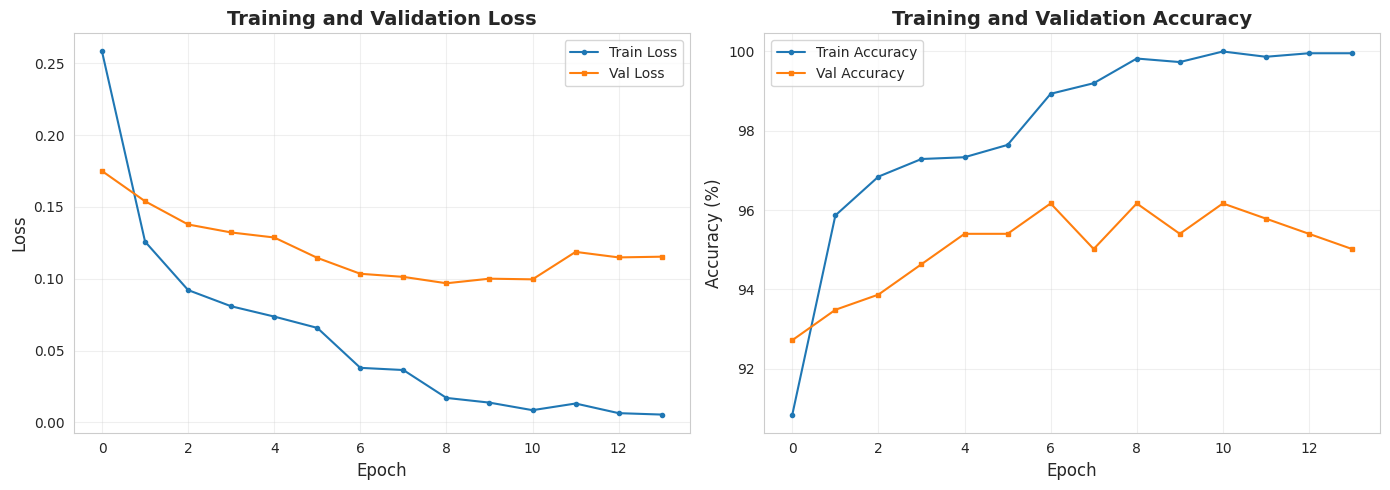


Final Training Metrics
Best validation accuracy: 96.17%
Final training loss: 0.0054
Final validation loss: 0.1153


In [21]:
# Plot training curves
print("Plotting training history...")
plot_training_history(history)

# Print final metrics
print("\n" + "="*70)
print("Final Training Metrics")
print("="*70)
print(f"Best validation accuracy: {max(history['val_acc']):.2f}%")
print(f"Final training loss: {history['train_loss'][-1]:.4f}")
print(f"Final validation loss: {history['val_loss'][-1]:.4f}")
print("="*70)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Model loaded from: ./weights/densenet121_best.pth

Evaluating on test set...


Test evaluation: 100%|██████████| 9/9 [00:03<00:00,  2.39it/s]



Classification Report
               precision    recall  f1-score   support

Not Fractured     0.8571    0.6000    0.7059        20
    Fractured     0.9676    0.9917    0.9795       241

     accuracy                         0.9617       261
    macro avg     0.9124    0.7959    0.8427       261
 weighted avg     0.9591    0.9617    0.9585       261

Confusion Matrix
[[ 12   8]
 [  2 239]]


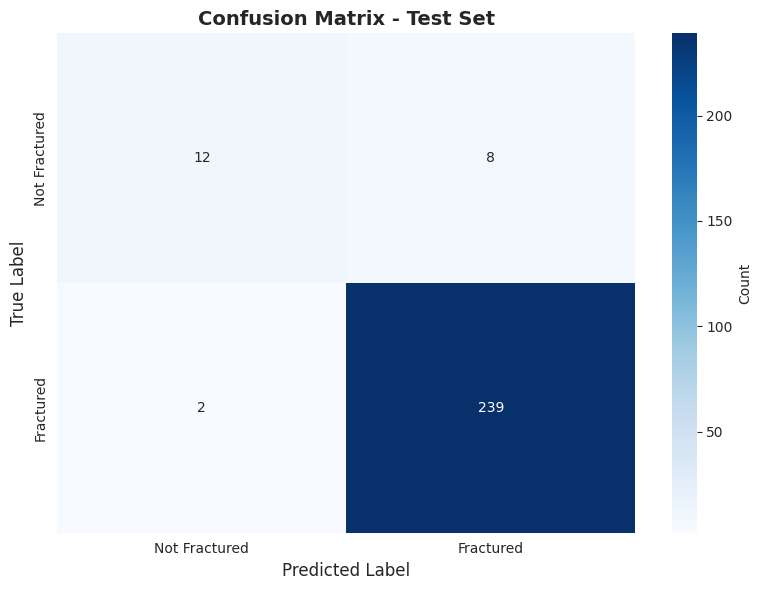

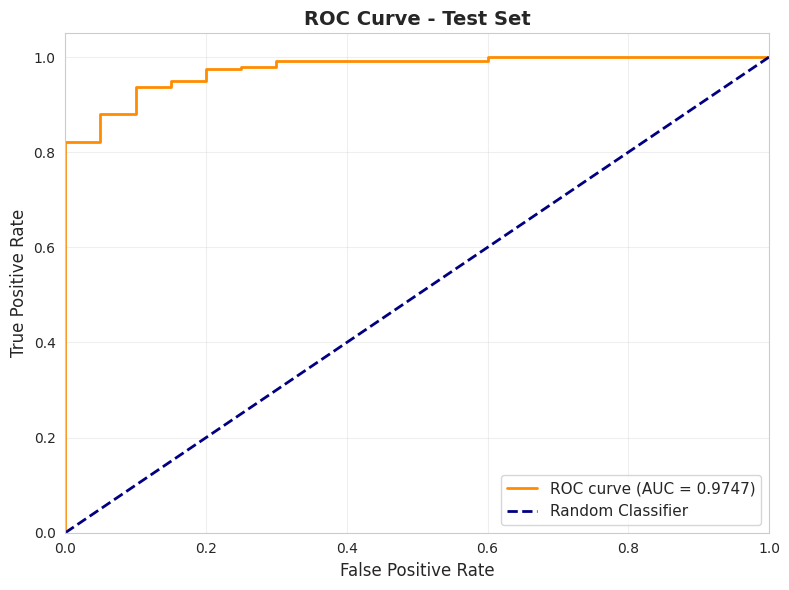

ROC AUC Score: 0.9747


In [22]:
# Load best model
best_model = load_model(
    checkpoint_path=os.path.join(SAVE_DIR, 'densenet121_best.pth'),
    device=DEVICE
)

# Evaluate on test set
evaluate_on_test(best_model, test_loader, DEVICE)

In [23]:
# Example: Single image prediction
# Replace 'sample_xray.jpg' with actual image path
sample_image_path = '/kaggle/input/datasets/orvile/bone-fracture-dataset/Bone fracture dataset/Bone fracture dataset/Dataset/fracture/0.png'

# Check if sample image exists
if os.path.exists(sample_image_path):
    print(f"Predicting on: {sample_image_path}\n")
    result = predict_single_image(
        best_model,
        sample_image_path,
        device=DEVICE
    )
    
    print("="*70)
    print("Prediction Result")
    print("="*70)
    print(f"Prediction: {result['prediction']}")
    print(f"Confidence: {result['confidence']:.4f}")
    print(f"\nProbabilities:")
    for class_name, prob in result['probabilities'].items():
        print(f"  {class_name}: {prob:.4f}")
    print("="*70)
else:
    print(f"Sample image not found at: {sample_image_path}")
    print("To test single image prediction, provide a valid image path.")
    print("\nExample usage:")
    print("  result = predict_single_image(best_model, 'path/to/image.jpg', device=DEVICE)")
    print("  print(result)")

Predicting on: /kaggle/input/datasets/orvile/bone-fracture-dataset/Bone fracture dataset/Bone fracture dataset/Dataset/fracture/0.png

Prediction Result
Prediction: Fractured
Confidence: 0.9981

Probabilities:
  Fractured: 0.9981
  Not Fractured: 0.0019
